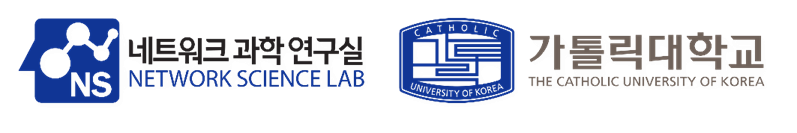

<h1><center><b>💻 Solution 2:</b> </br>👋 Message Passing Mechanism & Graph Neural Network</center></h1>

### Given karate graph dataset from Practice Code

### Assignment 1. Implement label propagation (relational classification) to infer labels for unlabeled nodes and visualize the predicted labels on the karate graph

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
from torch_geometric.datasets import KarateClub
from torch_geometric.utils import to_networkx

/home/linux/miniconda3/envs/GNN/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/linux/miniconda3/envs/GNN/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
import torch

# Loading Karate Graph
data = KarateClub()[0]
club_graph = nx.karate_club_graph()

# Original two-way split used in the practice notebook
data.y = torch.tensor(
    [0 if club_graph.nodes[node]["club"] == "Mr. Hi" else 1 for node in range(data.num_nodes)],
    dtype=torch.long,
)
data.train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
data.train_mask[0] = True   # Mr. Hi
data.train_mask[33] = True  # Officer

karate_graph = to_networkx(data, to_undirected=True)
for node in karate_graph.nodes():
    karate_graph.nodes[node]["class"] = int(data.y[node])

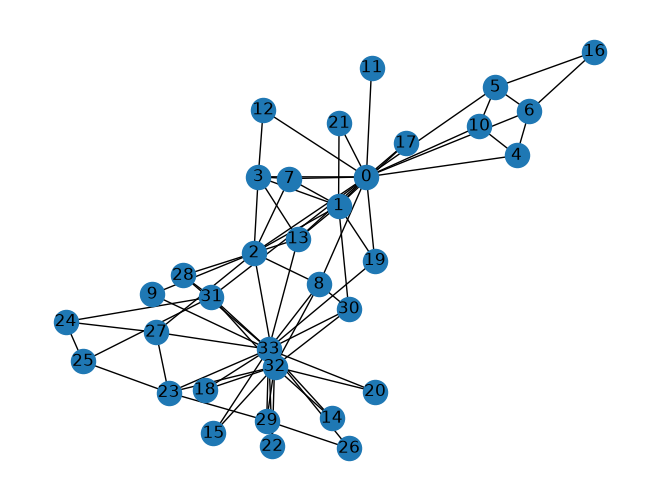

In [3]:
nx.draw(karate_graph, with_labels=True)

In [4]:
def binary_label_propagation(graph, seed_labels, max_iters=30, seed=0):
    labeled = set(seed_labels.keys())
    Y = {n: float(seed_labels[n]) if n in labeled else 0.5 for n in graph.nodes}
    rng = random.Random(seed)

    for _ in range(max_iters):
        prev = dict(Y)
        unlabeled = [n for n in graph.nodes if n not in labeled]
        rng.shuffle(unlabeled)
        for v in unlabeled:
            neighbors = list(graph.neighbors(v))
            if not neighbors:
                continue
            Y[v] = sum(Y[u] for u in neighbors) / len(neighbors)
        if all(abs(Y[n] - prev[n]) < 1e-6 for n in graph.nodes):
            break

    pred = np.array([1 if Y[n] > 0.5 else 0 for n in range(graph.number_of_nodes())])
    return pred, Y

In [5]:
y_numpy = data.y.numpy()
lp_pred, lp_Y = binary_label_propagation(karate_graph, {0: 0, 33: 1}, max_iters=30, seed=0)

unlabeled_mask = ~data.train_mask.numpy()
print("Labeled seed nodes:", [0, 33])
print("Predicted labels:", lp_pred.tolist())
print("True labels:     ", y_numpy.tolist())
print(f"Unlabeled accuracy: {(lp_pred[unlabeled_mask] == y_numpy[unlabeled_mask]).mean():.4f}")
print(f"Full-graph accuracy: {(lp_pred == y_numpy).mean():.4f}")

Labeled seed nodes: [0, 33]
Predicted labels: [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
True labels:      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Unlabeled accuracy: 0.9688
Full-graph accuracy: 0.9706


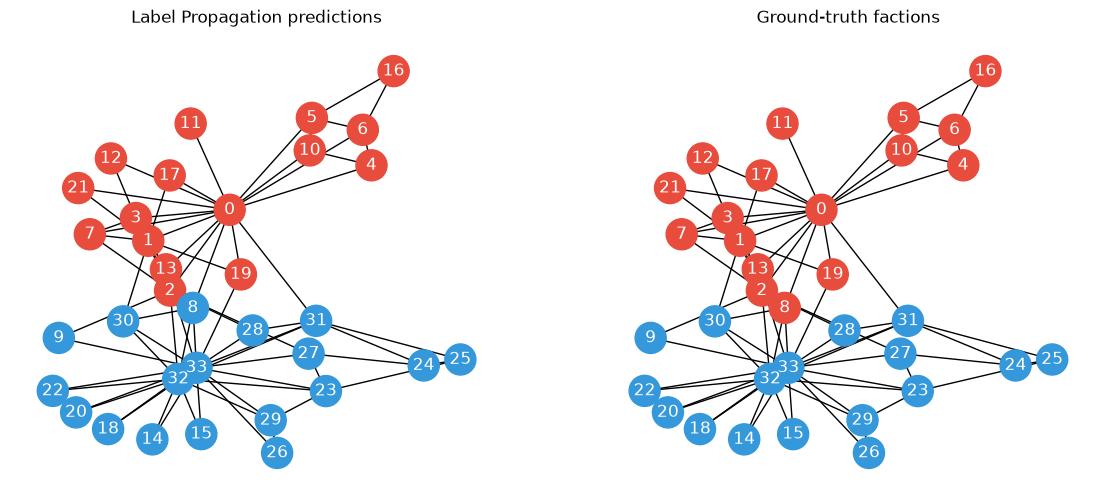

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pos = nx.spring_layout(karate_graph, seed=42)
colors = {0: "#E74C3C", 1: "#3498DB"}

nx.draw(
    karate_graph, pos, ax=axes[0], with_labels=True,
    node_color=[colors[int(c)] for c in lp_pred], node_size=500, font_color="white",
)
axes[0].set_title("Label Propagation predictions")

nx.draw(
    karate_graph, pos, ax=axes[1], with_labels=True,
    node_color=[colors[int(c)] for c in y_numpy], node_size=500, font_color="white",
)
axes[1].set_title("Ground-truth factions")
plt.show()

### Assignment 2. Implement the GCN model to learn the representations for each node, perform node classification, and visualizing the node embeddings via TSNE or PCA

In [7]:
import torch
import torch.nn.functional as F
from sklearn.manifold import TSNE

In [8]:
def build_gcn_normalized_adjacency(edge_index, num_nodes):
    # Build the dense adjacency matrix A
    A = torch.zeros((num_nodes, num_nodes), dtype=torch.float)
    A[edge_index[0], edge_index[1]] = 1.0

    # Add self-loops: A_tilde = A + I
    A_tilde = A + torch.eye(num_nodes)

    # Symmetric normalization D_tilde^{-1/2} A_tilde D_tilde^{-1/2}
    deg = A_tilde.sum(dim=1)
    D_inv_sqrt = torch.diag(deg.clamp(min=1.0).pow(-0.5))
    return D_inv_sqrt @ A_tilde @ D_inv_sqrt


class GCNLayer(torch.nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.W = torch.nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, H, A_hat, activation=True):
        out = A_hat @ self.W(H)
        return torch.relu(out) if activation else out


class ScratchGCN(torch.nn.Module):
    def __init__(self, in_dim, hidden_dim, num_classes):
        super().__init__()
        self.conv1 = GCNLayer(in_dim, hidden_dim)
        self.conv2 = GCNLayer(hidden_dim, num_classes)

    def forward(self, x, A_hat, return_embeddings=False):
        h = self.conv1(x, A_hat, activation=True)
        if return_embeddings:
            return h
        return self.conv2(h, A_hat, activation=False)

In [9]:
def train_gcn(model, x, A_hat, y, train_mask, epochs=200, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        logits = model(x, A_hat)
        loss = F.cross_entropy(logits[train_mask], y[train_mask])
        loss.backward()
        optimizer.step()

        if epoch % 20 == 0 or epoch == 1:
            pred = logits.argmax(dim=1)
            train_acc = (pred[train_mask] == y[train_mask]).float().mean().item()
            full_acc = (pred == y).float().mean().item()
            print(
                f"Epoch {epoch:03d} | loss={loss.item():.4f} "
                f"| train acc={train_acc:.4f} | full-graph acc={full_acc:.4f}"
            )

    return model


A_hat = build_gcn_normalized_adjacency(data.edge_index, data.num_nodes)
torch.manual_seed(42)
gcn = ScratchGCN(data.x.size(1), hidden_dim=16, num_classes=2)
gcn = train_gcn(gcn, data.x, A_hat, data.y, data.train_mask, epochs=200, lr=0.01)

Epoch 001 | loss=0.6926 | train acc=0.5000 | full-graph acc=0.4706
Epoch 020 | loss=0.3983 | train acc=1.0000 | full-graph acc=1.0000
Epoch 040 | loss=0.0887 | train acc=1.0000 | full-graph acc=0.9706
Epoch 060 | loss=0.0157 | train acc=1.0000 | full-graph acc=0.9706
Epoch 080 | loss=0.0071 | train acc=1.0000 | full-graph acc=0.9706
Epoch 100 | loss=0.0052 | train acc=1.0000 | full-graph acc=0.9706
Epoch 120 | loss=0.0045 | train acc=1.0000 | full-graph acc=0.9706
Epoch 140 | loss=0.0041 | train acc=1.0000 | full-graph acc=0.9706
Epoch 160 | loss=0.0039 | train acc=1.0000 | full-graph acc=0.9706
Epoch 180 | loss=0.0037 | train acc=1.0000 | full-graph acc=0.9706
Epoch 200 | loss=0.0035 | train acc=1.0000 | full-graph acc=0.9706


GCN train accuracy: 1.0000
GCN full-graph accuracy: 0.9706


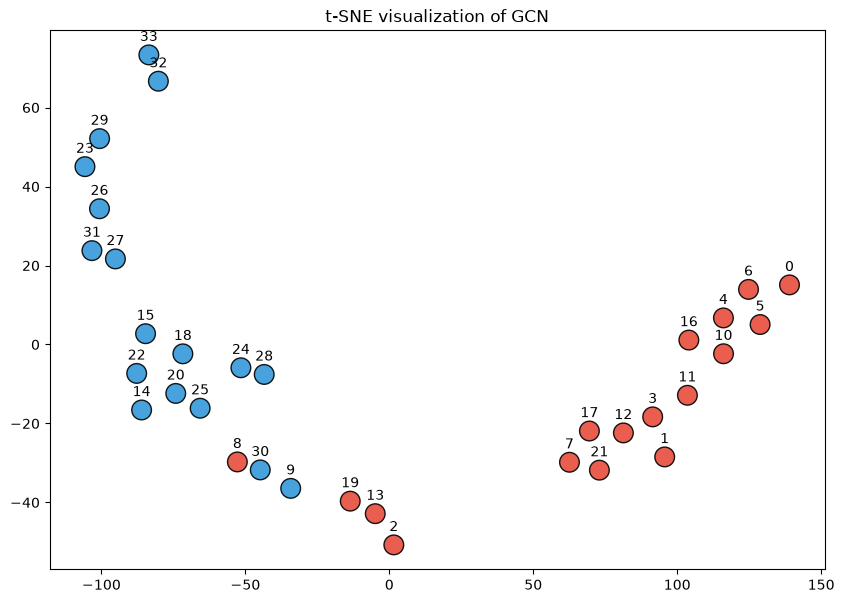

In [10]:
def visualize_embeddings(model, x, A_hat, y, karate_graph):
    model.eval()
    with torch.no_grad():
        node_embeddings = model(x, A_hat, return_embeddings=True).cpu().numpy()
        logits = model(x, A_hat)
        pred = logits.argmax(dim=1)
        train_acc = (pred[data.train_mask] == data.y[data.train_mask]).float().mean().item()
        full_acc = (pred == data.y).float().mean().item()

    print(f"GCN train accuracy: {train_acc:.4f}")
    print(f"GCN full-graph accuracy: {full_acc:.4f}")

    tsne = TSNE(n_components=2, random_state=42, perplexity=5)
    embeddings_2d = tsne.fit_transform(node_embeddings)
    colors = ["#E74C3C" if int(c) == 0 else "#3498DB" for c in y.numpy()]

    plt.figure(figsize=(10, 7))
    plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], s=200, c=colors, edgecolors="black", alpha=0.9)
    for i, node in enumerate(karate_graph.nodes()):
        plt.annotate(
            str(node),
            (embeddings_2d[i, 0], embeddings_2d[i, 1]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
        )
    plt.title("t-SNE visualization of GCN")
    plt.show()


visualize_embeddings(gcn, data.x, A_hat, data.y, karate_graph)